In [151]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ydata_profiling import ProfileReport
%matplotlib inline
pd.set_option('display.max_columns',None)

In [152]:
optimized_dtypes = {
    'subject_age':'Int8',
    'location': 'category',
    'subject_race': 'category',
    'subject_sex': 'category',
    'officer_race': 'category',
    'officer_sex': 'category',
    'type': 'category',
    'violation': 'category',
    'outcome': 'category',
    'vehicle_make': 'category',
    'vehicle_model': 'category',
    # Use Pandas' nullable boolean for contraband columns to handle missing values
    'contraband_found': 'boolean',
    'contraband_drugs': 'boolean',
    'contraband_weapons': 'boolean',
    'contraband_other': 'boolean',
    # Standard booleans
    'arrest_made': 'bool',
    'citation_issued': 'bool',
    'contraband_alcohol': 'bool',
    'search_conducted': 'bool',
    'search_person': 'bool',
    'search_vehicle': 'bool'
}

df = pd.read_csv(
    '~/Machine Learning/EDA/Project/stops.csv',       
    dtype=optimized_dtypes, 
    parse_dates=['datetime']
)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2091119 entries, 0 to 2091118
Data columns (total 25 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   location                  category      
 1   lat                       float64       
 2   lng                       float64       
 3   subject_age               Int8          
 4   subject_race              category      
 5   subject_sex               category      
 6   officer_race              category      
 7   officer_sex               category      
 8   officer_years_of_service  float64       
 9   type                      category      
 10  violation                 category      
 11  arrest_made               bool          
 12  citation_issued           bool          
 13  outcome                   category      
 14  contraband_found          boolean       
 15  contraband_drugs          boolean       
 16  contraband_weapons        boolean       
 17  contraba

In [13]:
profile=ProfileReport(df)
profile.to_file('stops.html')

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 25/25 [00:17<00:00,  1.45it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [153]:
df=df.drop_duplicates()

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2091107 entries, 0 to 2091118
Data columns (total 25 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   location                  category      
 1   lat                       float64       
 2   lng                       float64       
 3   subject_age               Int8          
 4   subject_race              category      
 5   subject_sex               category      
 6   officer_race              category      
 7   officer_sex               category      
 8   officer_years_of_service  float64       
 9   type                      category      
 10  violation                 category      
 11  arrest_made               bool          
 12  citation_issued           bool          
 13  outcome                   category      
 14  contraband_found          boolean       
 15  contraband_drugs          boolean       
 16  contraband_weapons        boolean       
 17  contraband_al

#### Univariate Analysis

##### numerical

In [6]:
df['subject_age'].describe()

count    1467059.0
mean     36.396419
std      13.365548
min           10.0
25%           26.0
50%           33.0
75%           45.0
max          100.0
Name: subject_age, dtype: Float64

In [7]:
df['subject_age'].info()

<class 'pandas.core.series.Series'>
Index: 2091107 entries, 0 to 2091118
Series name: subject_age
Non-Null Count    Dtype
--------------    -----
1467059 non-null  Int8 
dtypes: Int8(1)
memory usage: 19.9 MB


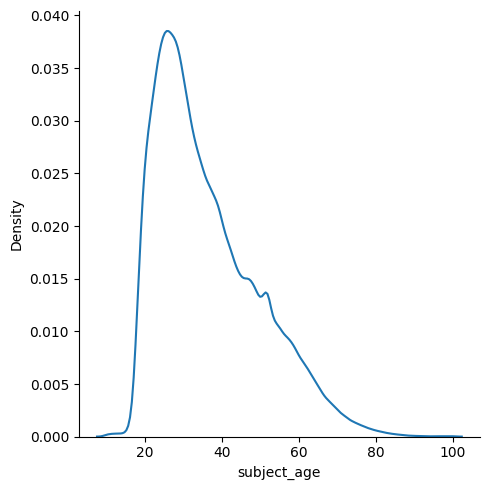

In [8]:
sns.displot(data=df,x='subject_age',kind='kde')

In [9]:
df['subject_age'].skew()

np.float64(0.8731963756160505)

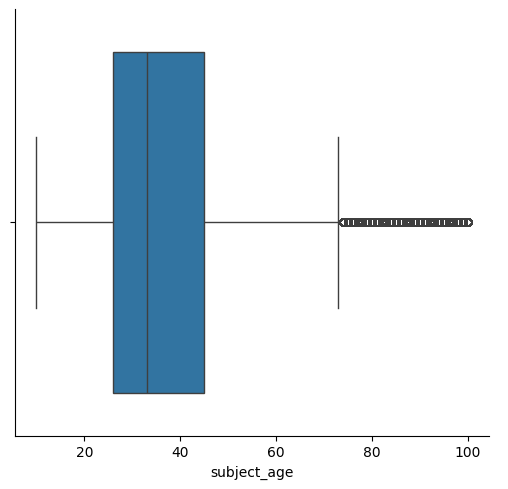

In [10]:
sns.catplot(data=df,x='subject_age',kind='box')

In [154]:
#converting the mistyped ages to nan
df.loc[df['subject_age']<16,'subject_age']=np.nan

##### Datetime

In [155]:
df['month']=df['datetime'].dt.month_name().astype('category')
df['weekday']=df['datetime'].dt.day_name().astype('category')
df['time']=df['datetime'].dt.time
df['date']=df['datetime'].dt.date

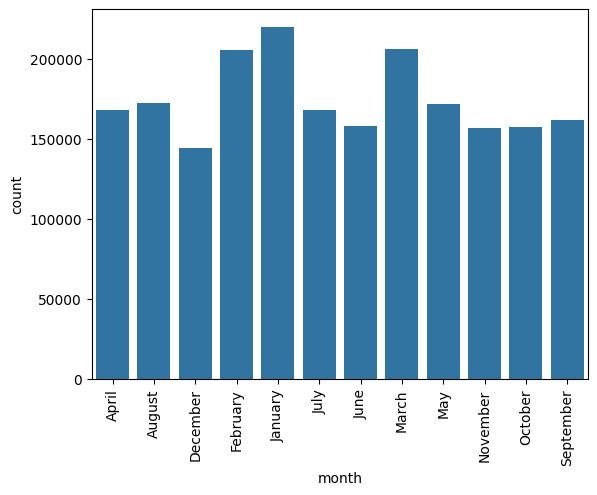

In [156]:
sns.countplot(data=df,x='month')
plt.xticks(rotation='vertical')
plt.show()

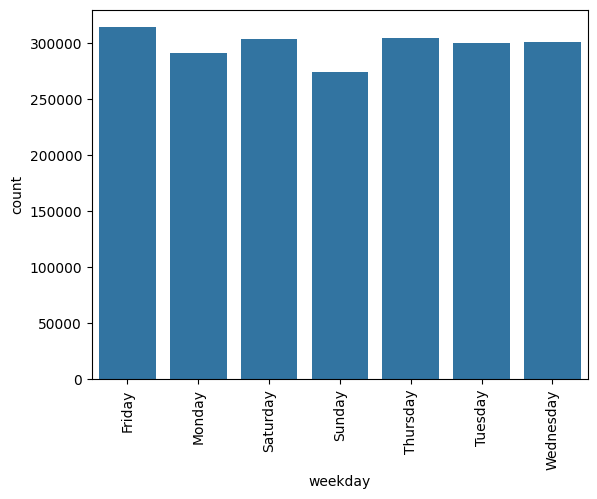

In [157]:
sns.countplot(data=df,x='weekday')
plt.xticks(rotation='vertical')
plt.show()

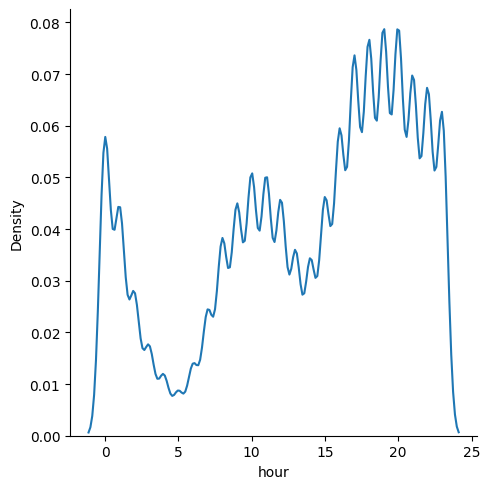

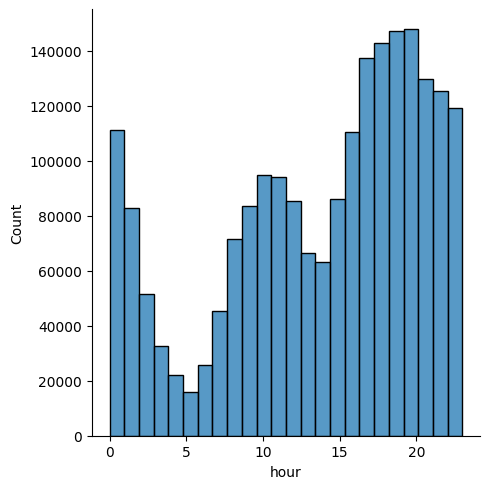

In [158]:

df['hour'] = df['datetime'].dt.hour

sns.displot(data=df, x='hour', kind='kde')
plt.show()


sns.displot(data=df, x='hour', kind='hist', bins=24)
plt.show()

In [159]:
df.head()

,location,lat,lng,subject_age,subject_race,subject_sex,officer_race,officer_sex,officer_years_of_service,type,violation,arrest_made,citation_issued,outcome,contraband_found,contraband_drugs,contraband_weapons,contraband_alcohol,contraband_other,search_conducted,search_person,search_vehicle,vehicle_make,vehicle_model,datetime,month,weekday,time,date,hour
0,700 LINCOLN W,41.874405,-88.216690,23,black,male,white,male,17.0,vehicular,DRIVING ON SUSPENDED LICENSE,True,False,arrest,<NA>,<NA>,<NA>,False,<NA>,False,False,False,NaN,NaN,2012-01-06 09:00:00,January,Friday,09:00:00,2012-01-06,9
1,NaN,NaN,NaN,23,hispanic,male,white,male,2.0,vehicular,DRIVING/NEVER ISSUED LICENSE,True,False,arrest,<NA>,<NA>,<NA>,False,<NA>,False,False,False,NaN,NaN,2012-01-01 00:00:00,January,Sunday,00:00:00,2012-01-01,0
2,0 NORTHWEST HWY & HILLSIDE RD S,42.146703,-88.119549,38,white,female,NaN,NaN,NaN,vehicular,DRIVING ON SUSPENDED LICENSE,True,False,arrest,<NA>,<NA>,<NA>,False,<NA>,False,False,False,NaN,NaN,2012-01-01 01:00:00,January,Sunday,01:00:00,2012-01-01,1
3,108 LAMON AVE N,41.882072,-87.747829,35,black,male,black,male,8.0,vehicular,IVC - FAIL TO STOP/SIGNAL CROSSWALK,True,False,arrest,<NA>,<NA>,<NA>,False,<NA>,False,False,False,NaN,NaN,2012-01-01 01:00:00,January,Sunday,01:00:00,2012-01-01,1
4,3451 177TH ST W,41.567987,-87.701027,20,black,male,NaN,NaN,NaN,vehicular,IVC - DRIVING 15-20 MPH ABOVE SPEED LIMIT,True,False,arrest,<NA>,<NA>,<NA>,False,<NA>,False,False,False,NaN,NaN,2012-01-01 01:00:00,January,Sunday,01:00:00,2012-01-01,1


In [160]:
# Set the datetime column as the DataFrame index
df.set_index('datetime', inplace=True)

In [176]:
df.reset_index(inplace=True)

In [177]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2091107 entries, 0 to 2091106
Data columns (total 30 columns):
 #   Column                    Dtype         
---  ------                    -----         
 0   datetime                  datetime64[ns]
 1   location                  category      
 2   lat                       float64       
 3   lng                       float64       
 4   subject_age               Int8          
 5   subject_race              category      
 6   subject_sex               category      
 7   officer_race              category      
 8   officer_sex               category      
 9   officer_years_of_service  float64       
 10  type                      category      
 11  violation                 category      
 12  arrest_made               bool          
 13  citation_issued           bool          
 14  outcome                   category      
 15  contraband_found          boolean       
 16  contraband_drugs          boolean       
 17  contraba

In [178]:
import gc

# Delete the profile report object if it's still in memory
del profile 

# Force Python to clear freed memory
gc.collect()

NameError: name 'profile' is not defined

##### categorical

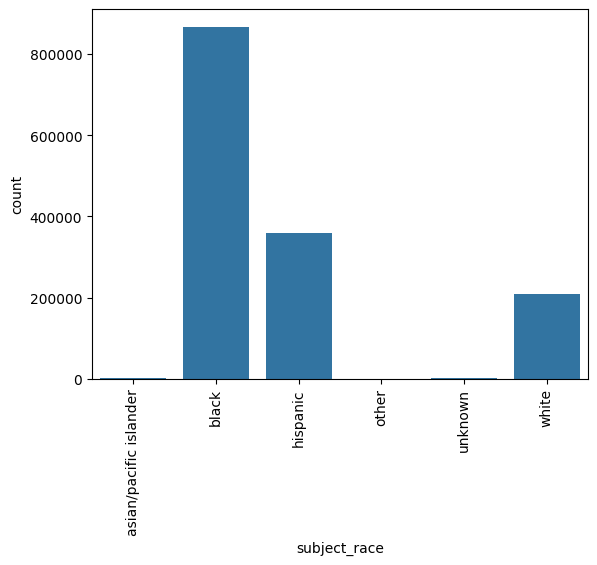

In [179]:
sns.countplot(data=df,x='subject_race')
plt.xticks(rotation=90)
plt.show()

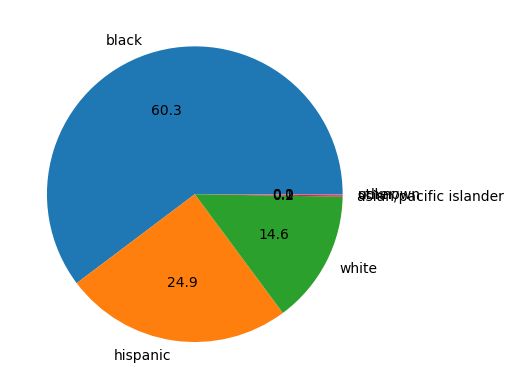

In [180]:
plt.pie(df['subject_race'].value_counts(),labels=df['subject_race'].value_counts().index,autopct='%1.1f')
plt.show()

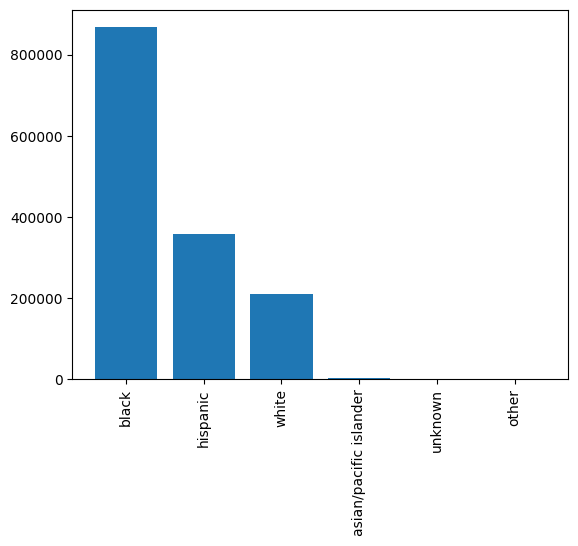

In [181]:
plt.bar(df['subject_race'].value_counts().index,height=df['subject_race'].value_counts().values)
plt.xticks(rotation=90)
plt.show()

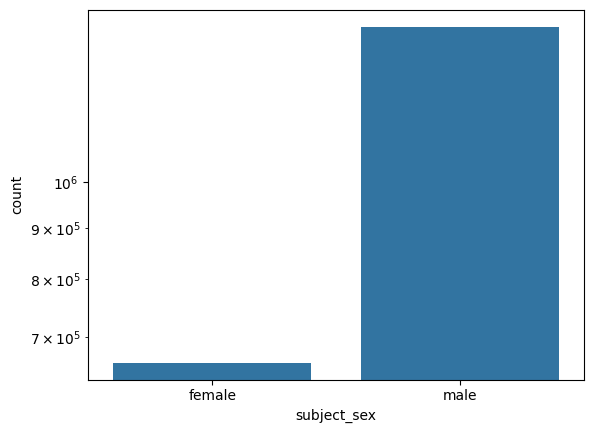

In [182]:
sns.countplot(data=df,x='subject_sex')
plt.yscale('log')

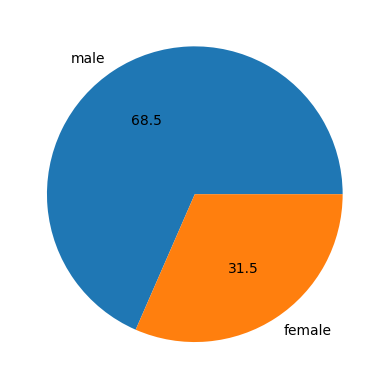

In [183]:
plt.pie(df['subject_sex'].value_counts(),autopct='%1.1f',labels=df['subject_sex'].value_counts().index)
plt.show()

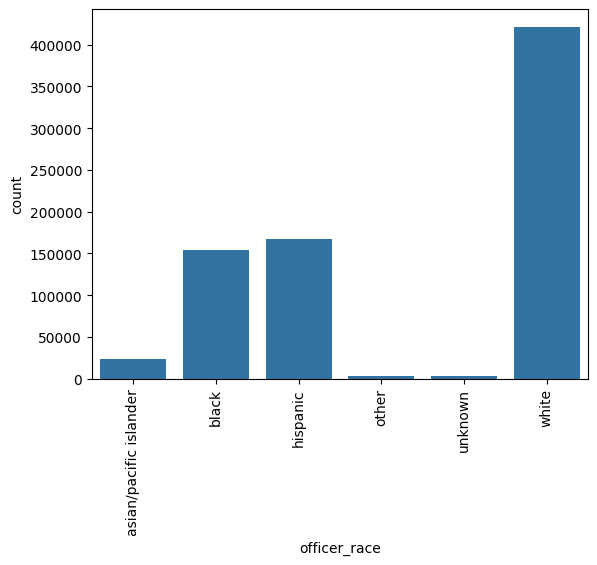

In [184]:
sns.countplot(data=df,x='officer_race')
plt.xticks(rotation=90)
plt.show()

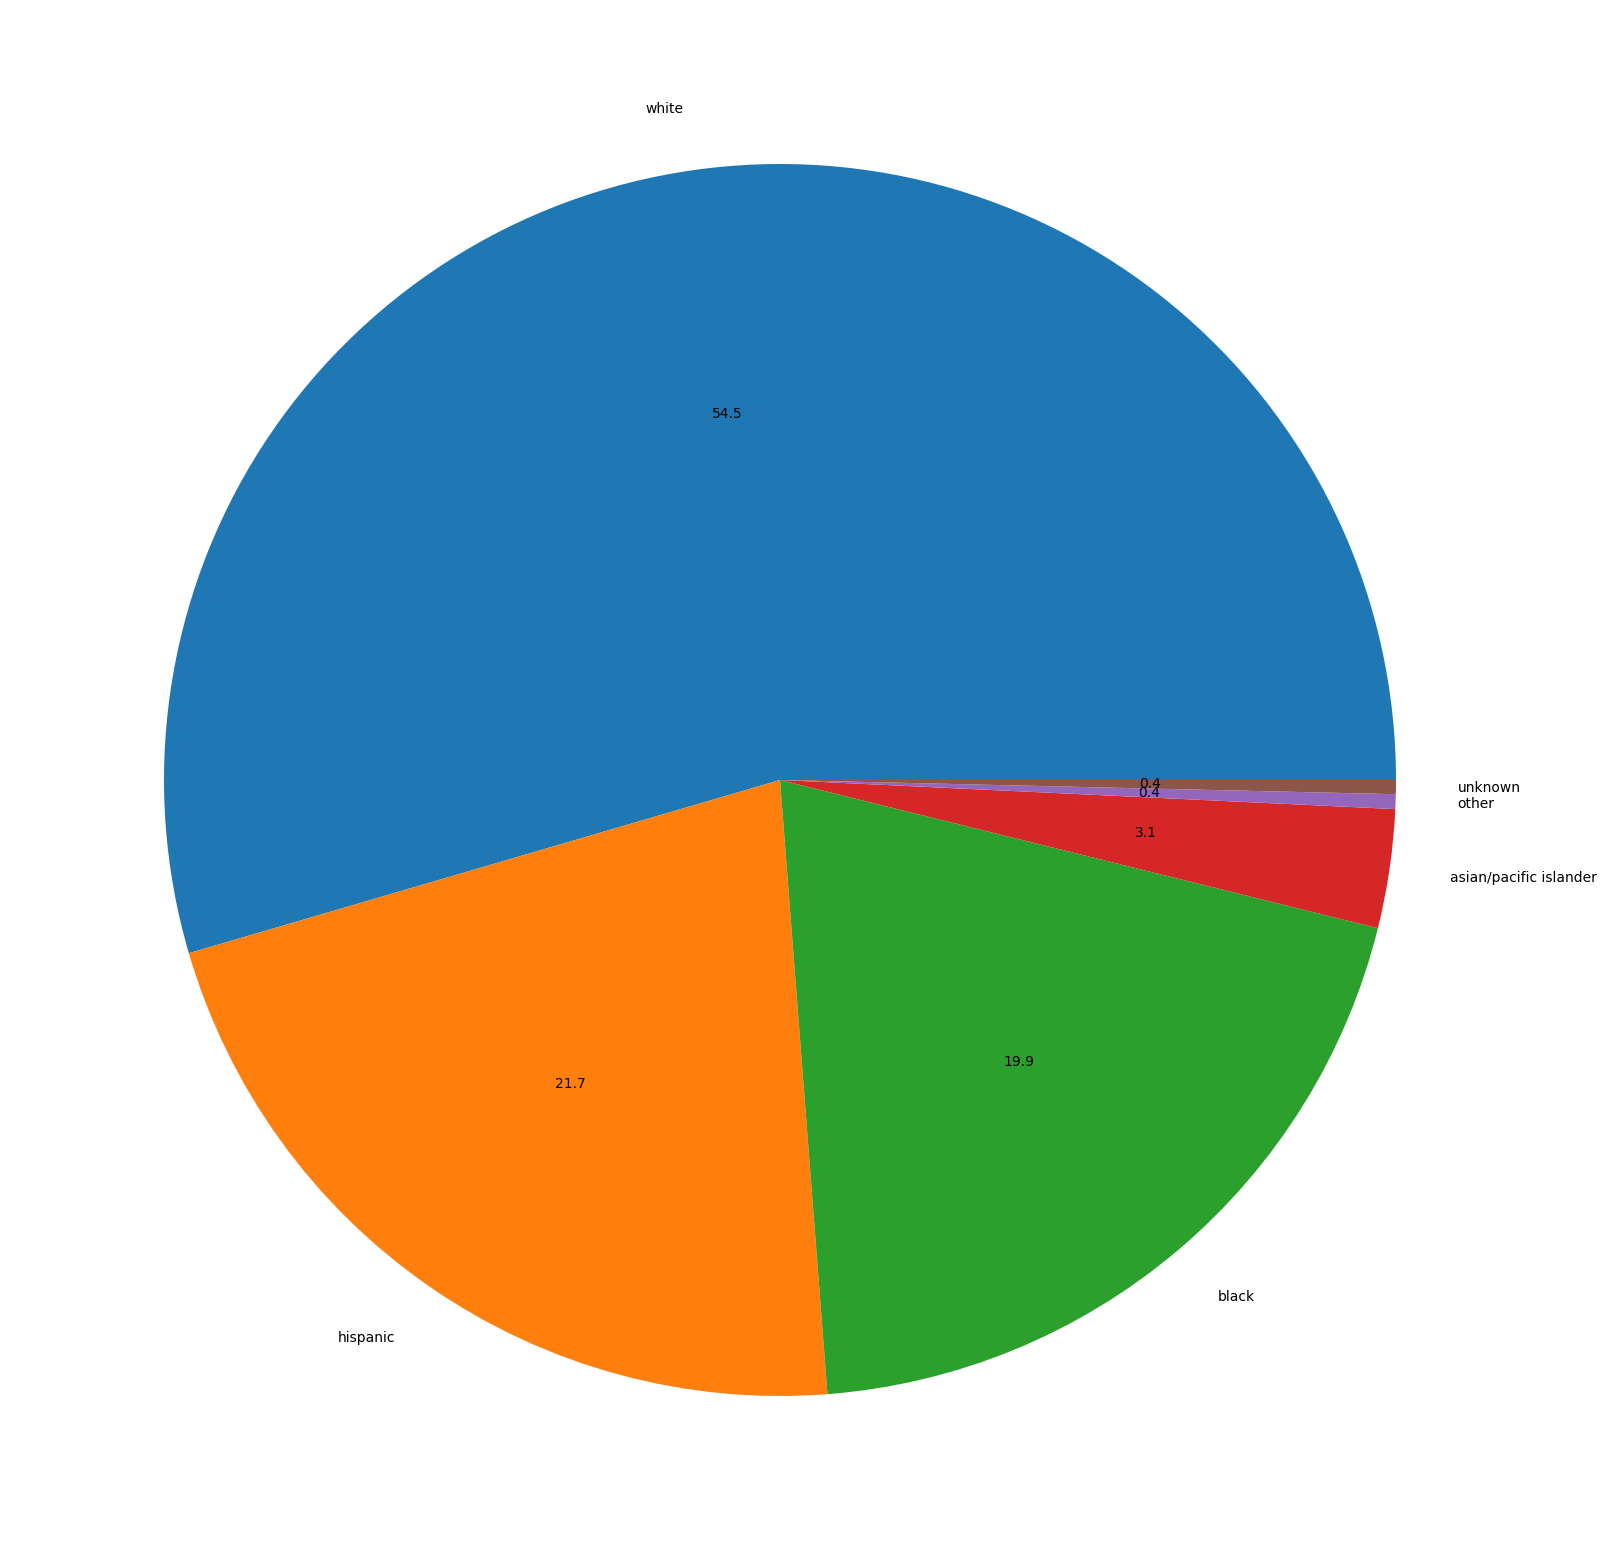

In [185]:
plt.figure(figsize=(20,20))
plt.pie(df['officer_race'].value_counts(),autopct='%1.1f',labels=df['officer_race'].value_counts().index)
plt.show()

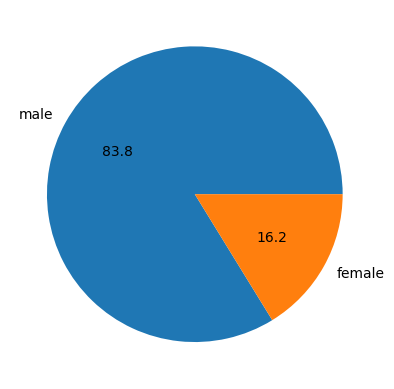

In [186]:
plt.pie(df['officer_sex'].value_counts(),autopct='%1.1f',labels=df['officer_sex'].value_counts().index)
plt.show()

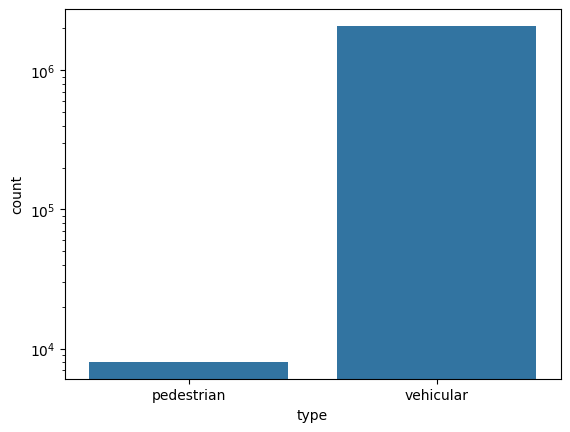

In [187]:
sns.countplot(data=df,x='type')
plt.yscale('log')
plt.show()

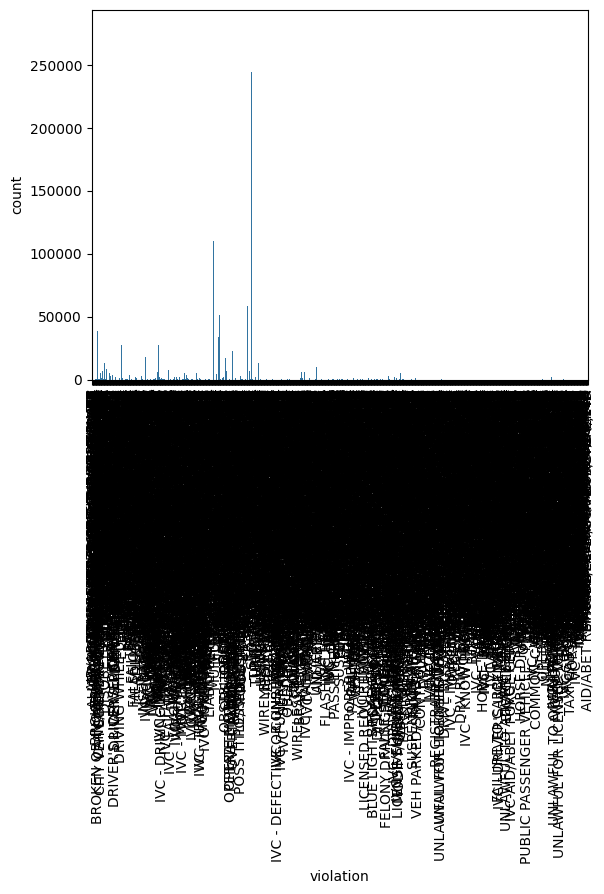

In [188]:
sns.countplot(data=df,x='violation')
plt.xticks(rotation=90)
plt.show()

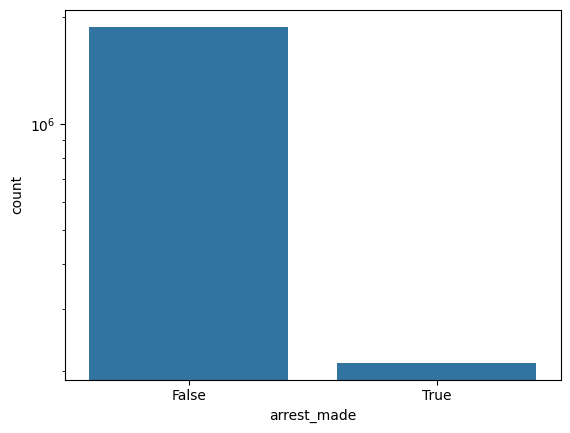

In [189]:
sns.countplot(data=df,x='arrest_made')
plt.yscale('log')

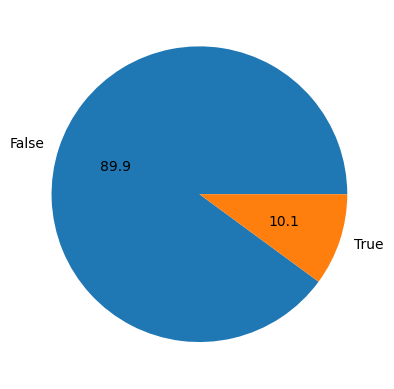

In [190]:
plt.pie(df['arrest_made'].value_counts().values,autopct='%1.1f',labels=df['arrest_made'].value_counts().index)
plt.show()

<Axes: xlabel='outcome', ylabel='count'>

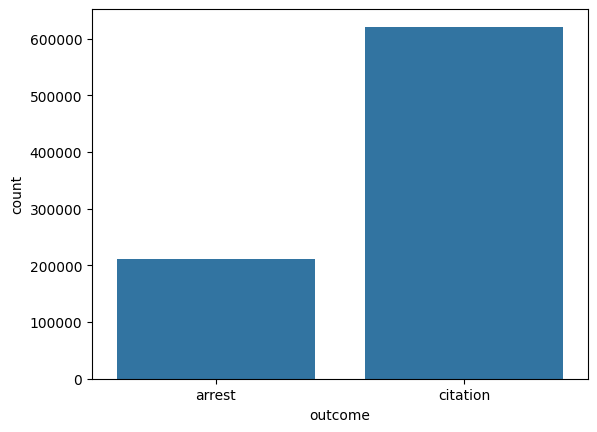

In [191]:
sns.countplot(data=df,x='outcome')

<Axes: xlabel='contraband_found', ylabel='count'>

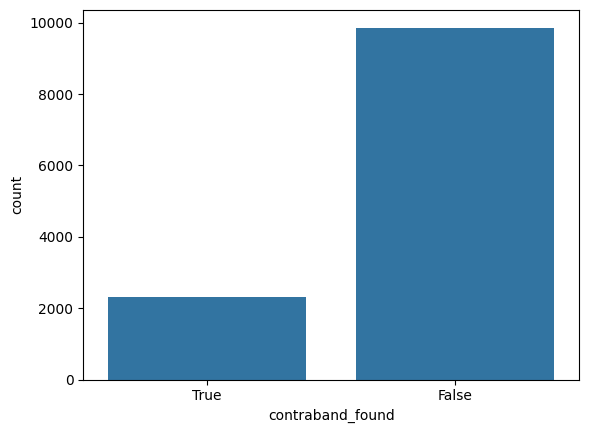

In [192]:
sns.countplot(data=df,x='contraband_found',order=['True','False'])

<Axes: xlabel='contraband_alcohol', ylabel='count'>

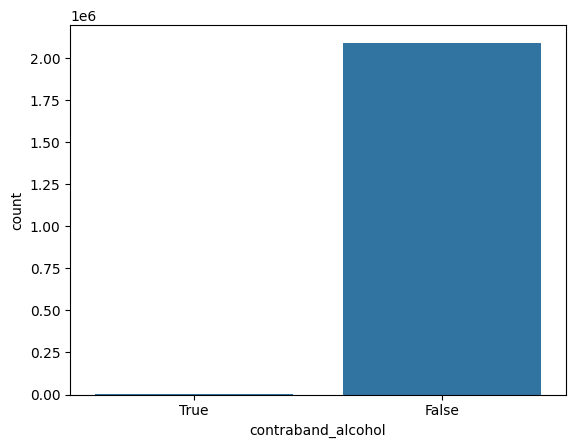

In [193]:
sns.countplot(data=df,x='contraband_alcohol',order=['True','False'])

<Axes: xlabel='contraband_weapons', ylabel='count'>

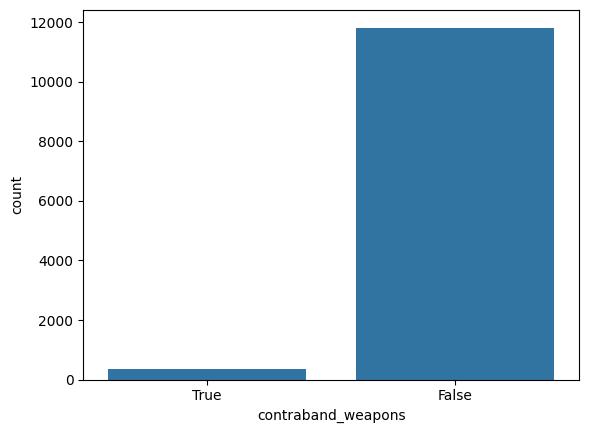

In [194]:
sns.countplot(data=df,x='contraband_weapons',order=['True','False'])

<Axes: xlabel='contraband_drugs', ylabel='count'>

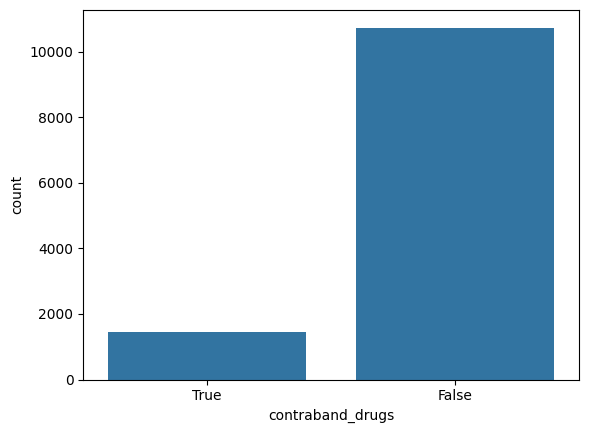

In [195]:
sns.countplot(data=df,x='contraband_drugs',order=['True','False'])

<Axes: xlabel='contraband_other', ylabel='count'>

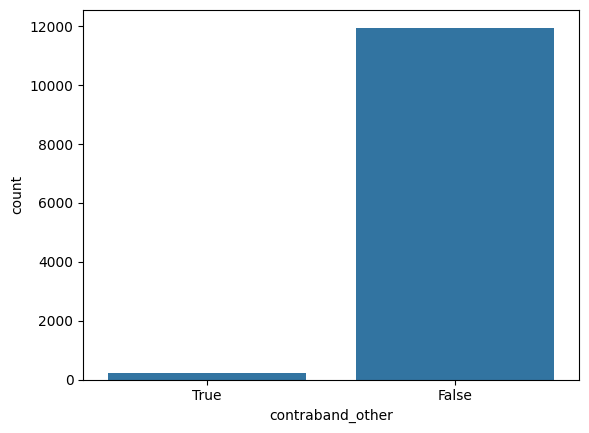

In [196]:
sns.countplot(data=df,x='contraband_other',order=['True','False'])

<Axes: xlabel='search_conducted', ylabel='count'>

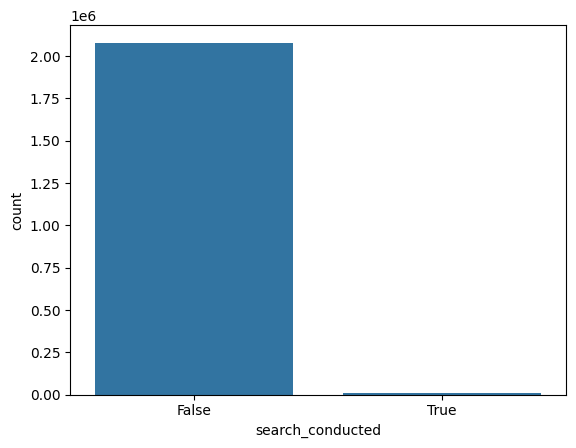

In [197]:
sns.countplot(data=df,x='search_conducted')

<Axes: xlabel='search_person', ylabel='count'>

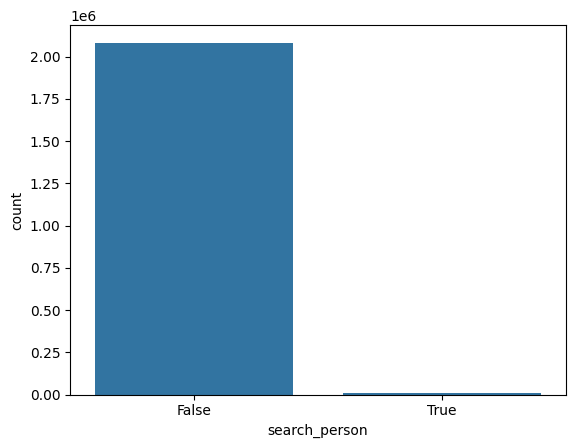

In [198]:
sns.countplot(data=df,x='search_person')

<Axes: xlabel='search_vehicle', ylabel='count'>

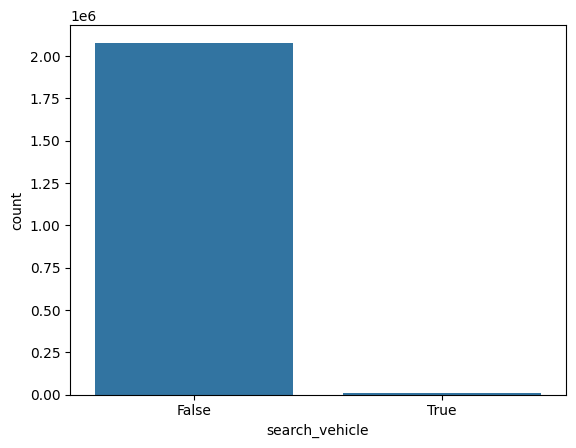

In [199]:
sns.countplot(data=df,x='search_vehicle')

In [200]:
df.to_parquet('stops.parquet')